# 01. EDA — 학습 데이터만으로 웨이퍼 맵 이해하기

평가 데이터는 잠가 두고 `load_train()`(54,355개)만 쓴다. 여기서 내린 결정은 `PROTOCOL.md`로 넘긴다.

확인할 질문
1. 데이터가 어떻게 생겼나 (칸 값, 크기)
2. 패턴은 얼마나 불균형한가
3. 패턴마다 어떻게 생겼나
4. 크기를 어떻게 맞출까
5. 맵 크기(제품)만으로 패턴을 맞힐 수 있나 → 지름길 위험
6. 같은 로트의 웨이퍼끼리 비슷한가 → 검증 데이터 나누는 방식
7. 기준 모델에 쓸 특징의 힌트

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from src.data import load_train, CLASSES

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CMAP = ListedColormap(["#ececec", "#9fc5a8", "#c0392b"])  # 0 칩 없음, 1 정상, 2 불량
ORDER = [c for c in CLASSES if c != "none"] + ["none"]

df = load_train()
df["h"] = df.wafer_map.map(lambda m: m.shape[0])
df["w"] = df.wafer_map.map(lambda m: m.shape[1])
df["fail_rate"] = df.wafer_map.map(lambda m: (m == 2).sum() / max(1, (m > 0).sum()))
df["size"] = df.h.astype(str) + "x" + df.w.astype(str)
print(f"학습 웨이퍼 {len(df):,}개, 로트 {df.lot.nunique():,}개")

학습 웨이퍼 54,355개, 로트 5,809개


## 1. 데이터 구조

In [2]:
values = np.unique(np.concatenate([np.unique(m) for m in df.wafer_map]))
print("칸 값 종류:", values, " (0 = 칩 없음, 1 = 정상 칩, 2 = 불량 칩)")
print("die_size 열 = 칩(1 또는 2) 개수와 일치하는 비율:", (df.die_size == df.wafer_map.map(lambda m: (m > 0).sum())).mean())
print(f"맵 크기 종류: {df['size'].nunique()}개, 가장 작은 맵 {df.wafer_map.map(np.size).min()}칸, 가장 큰 맵 {df.wafer_map.map(np.size).max():,}칸")

칸 값 종류: [0 1 2]  (0 = 칩 없음, 1 = 정상 칩, 2 = 불량 칩)
die_size 열 = 칩(1 또는 2) 개수와 일치하는 비율: 1.0
맵 크기 종류: 335개, 가장 작은 맵 45칸, 가장 큰 맵 28,611칸


## 2. 패턴 비율

,비율
label,
Center,0.0637
Donut,0.0075
Edge-Loc,0.0445
Edge-Ring,0.1574
Loc,0.0298
Near-full,0.0010
Random,0.0112
Scratch,0.0092
none,0.6757


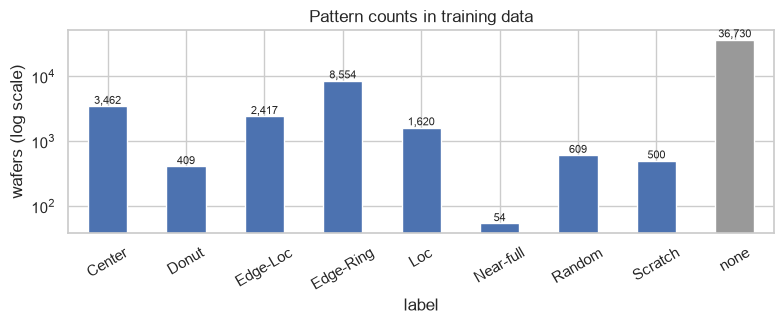

In [3]:
counts = df.label.value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(8, 3.4))
counts.plot.bar(ax=ax, color=["#4C72B0"] * 8 + ["#999999"], rot=30)
ax.set_yscale("log"); ax.set_ylabel("wafers (log scale)"); ax.set_title("Pattern counts in training data")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_class_counts.png", dpi=150)
(counts / counts.sum()).round(4).to_frame("비율")

**해석**
- `none`이 67.6%. 전부 `none`이라고만 해도 정확도 68%가 나온다. → 정확도 대신 **매크로 F1**(9개 패턴 F1의 단순 평균)과 **패턴별 재현율**을 본다.
- `Near-full`은 **54개**뿐이다. 이 패턴의 점수는 몇 개만 틀려도 크게 흔들린다.
- 세로축이 로그 눈금이다. 가장 많은 패턴과 가장 적은 패턴이 약 680배 차이 난다.

## 3. 패턴별 예시

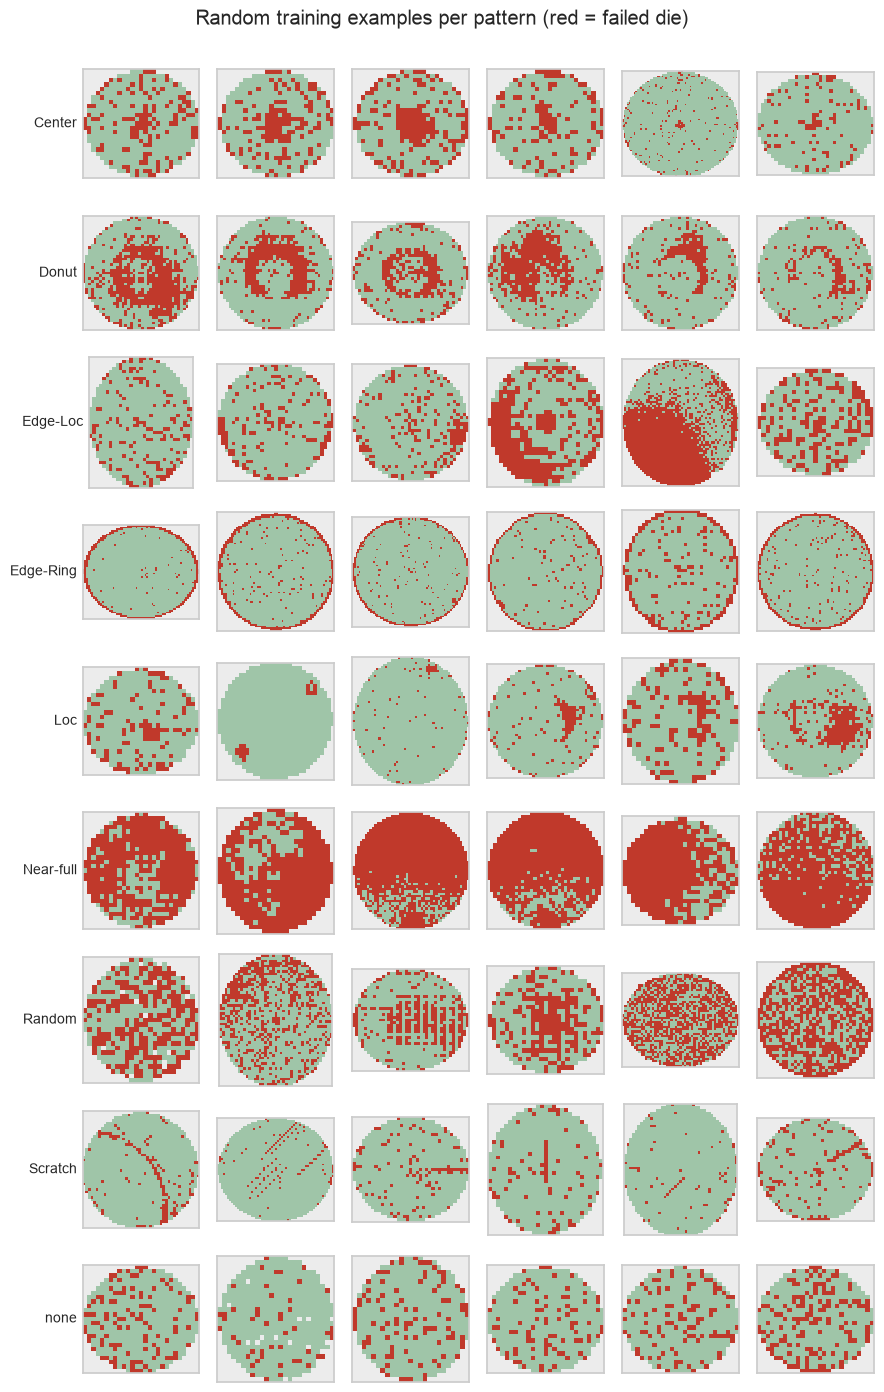

In [4]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(len(ORDER), 6, figsize=(9, 14))
for r, cls in enumerate(ORDER):
    rows = df[df.label == cls]
    for c, idx in enumerate(rng.choice(len(rows), 6, replace=False)):
        ax = axes[r, c]; ax.imshow(rows.wafer_map.iloc[idx], cmap=CMAP, vmin=0, vmax=2, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10)
fig.suptitle("Random training examples per pattern (red = failed die)", y=0.995)
fig.tight_layout(); fig.savefig(FIG_DIR / "02_examples.png", dpi=120)

**해석**
- Center, Edge-Ring, Near-full은 눈으로도 구분이 쉽다.
- Loc과 Edge-Loc은 "한 부분에 몰림"이라는 점이 같고, 위치(안쪽이냐 가장자리냐)만 다르다. 헷갈리기 쉬운 쌍이다.
- 패턴이 있는 맵에도 불량 칩이 여기저기 흩어져 있는 경우가 많다. 사람이 봐도 애매한 맵이 있다.
- 라벨이 의심스러운 예도 보인다. 예를 들어 Edge-Loc 줄의 4번째는 Donut처럼, Center 줄의 6번째는 none처럼 보인다.
  라벨은 사람이 붙인 것이라 오류가 섞여 있을 수 있다. 모델 점수에 상한이 있을 수 있다는 뜻이다.

## 4. 불량 칩 비율

,불량 칩 비율 중앙값
label,
Center,0.266
Donut,0.266
Edge-Loc,0.191
Edge-Ring,0.136
Loc,0.112
Near-full,0.877
Random,0.488
Scratch,0.056
none,0.152


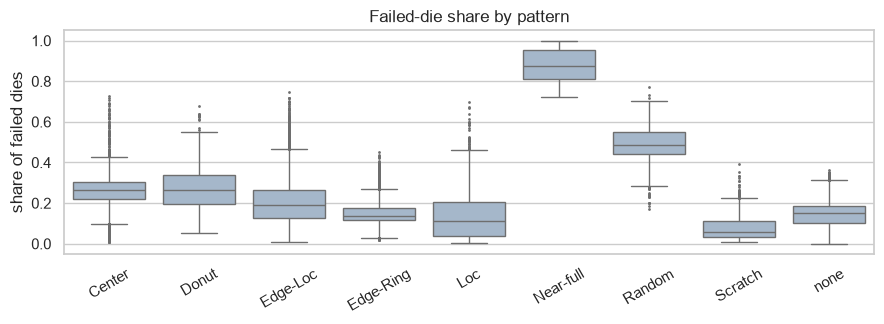

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.boxplot(data=df, x="label", y="fail_rate", order=ORDER, ax=ax, fliersize=1, color="#9fb7d0")
ax.set_xlabel(""); ax.set_ylabel("share of failed dies"); ax.set_title("Failed-die share by pattern")
plt.setp(ax.get_xticklabels(), rotation=30)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_fail_rate.png", dpi=150)
df.groupby("label").fail_rate.median().reindex(ORDER).round(3).to_frame("불량 칩 비율 중앙값")

**해석**: `Near-full`(중앙값 88%)과 `Random`(49%)은 불량 칩 비율만으로도 거의 구분된다. `Scratch`는 6%로 가장 낮다. 선 하나 정도만 불량이기 때문이다.
→ 불량 칩 비율은 기준 모델의 기본 특징으로 쓴다.

## 5. 영역별 불량 밀도: 기준 모델 특징의 힌트

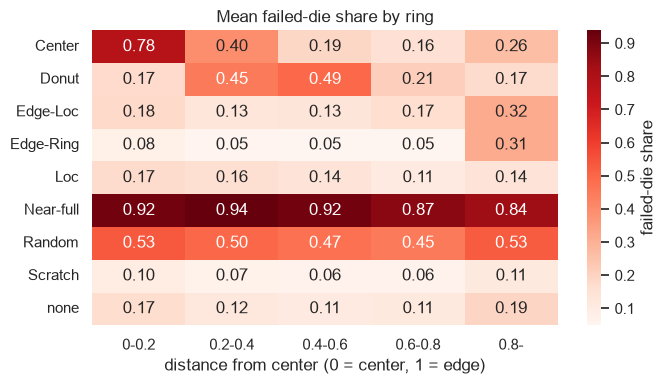

In [6]:
def radial_profile(m, bins=5):
    h, w = m.shape
    yy, xx = np.mgrid[0:h, 0:w]
    r = np.sqrt(((yy - (h - 1) / 2) / (h / 2)) ** 2 + ((xx - (w - 1) / 2) / (w / 2)) ** 2)
    die = m > 0
    edges = np.linspace(0, 1, bins + 1); edges[-1] = np.inf
    return [((m == 2) & die & (r >= a) & (r < b)).sum() / max(1, (die & (r >= a) & (r < b)).sum()) for a, b in zip(edges[:-1], edges[1:])]

prof = pd.DataFrame(df.wafer_map.map(radial_profile).tolist(), columns=["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-"])
prof["label"] = df.label.values
mean_prof = prof.groupby("label").mean().reindex(ORDER)

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(mean_prof, annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "failed-die share"}, ax=ax)
ax.set_xlabel("distance from center (0 = center, 1 = edge)"); ax.set_ylabel("")
ax.set_title("Mean failed-die share by ring")
fig.tight_layout(); fig.savefig(FIG_DIR / "04_radial_profile.png", dpi=150)

**해석**: 중심에서의 거리로 웨이퍼를 고리 5개로 나눠 불량 칩 비율을 봤다.
- `Center`: 가운데 고리가 가장 높고 바깥으로 갈수록 낮아진다.
- `Donut`: 가운데보다 그 바깥 고리가 높다.
- `Edge-Ring`: 가장 바깥 고리만 높다.

패턴이 "어디에" 몰려 있는지가 고리별 밀도로 잘 드러난다. → 기준 모델에 **고리별 불량 밀도**를 특징으로 쓴다.
- 다만 `Edge-Loc`(0.32)과 `Edge-Ring`(0.31)은 가장 바깥 고리 값이 거의 같다. "가장자리 일부"인지 "가장자리 전체"인지는 거리만으로 구분되지 않는다.
  → 기준 모델에 **방향별(부채꼴) 불량 밀도**도 넣어서, 불량이 한쪽에 몰렸는지 고르게 퍼졌는지를 알 수 있게 한다.
- `Scratch`나 `Loc`처럼 모양이나 한 부분이 중요한 패턴은 고리로는 잘 안 드러난다. CNN이 기준 모델보다 나을 수 있는 곳이다.

## 6. 크기 맞추기

In [7]:
longest = df[["h", "w"]].max(axis=1)
dist = pd.cut(longest, [0, 32, 48, 64, 96, 128, 1000], labels=["~32", "33~48", "49~64", "65~96", "97~128", "129~"]).value_counts().sort_index()
(dist / len(df)).round(3).to_frame("긴 변 기준 비율")

,긴 변 기준 비율
~32,0.612
33~48,0.202
49~64,0.128
65~96,0.038
97~128,0.006
129~,0.013


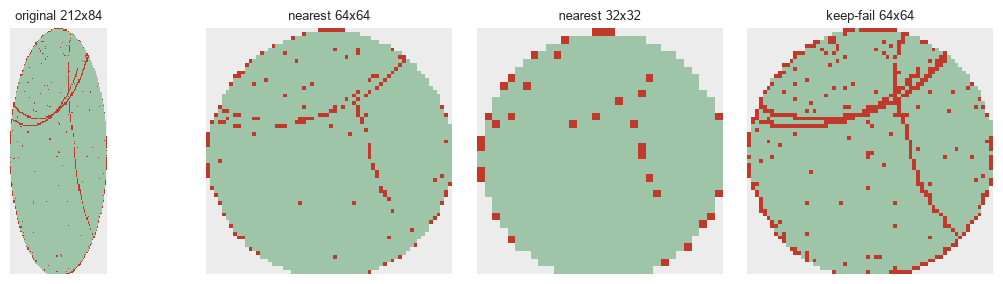

In [8]:
def resize_nearest(m, size):
    h, w = m.shape
    rows = (np.arange(size) * h / size).astype(int)
    cols = (np.arange(size) * w / size).astype(int)
    return m[np.ix_(rows, cols)]

def resize_keep_fail(m, size):
    # 줄일 때 한 칸에 여러 칸이 합쳐지면, 그중 불량이 하나라도 있으면 불량으로 둔다 (가는 선이 사라지지 않게)
    h, w = m.shape
    r_edges = np.linspace(0, h, size + 1).astype(int); c_edges = np.linspace(0, w, size + 1).astype(int)
    out = np.zeros((size, size), dtype=m.dtype)
    for i in range(size):
        for j in range(size):
            block = m[r_edges[i]:max(r_edges[i + 1], r_edges[i] + 1), c_edges[j]:max(c_edges[j + 1], c_edges[j] + 1)]
            out[i, j] = block.max()
    return out

big_scratch = df[(df.label == "Scratch") & (longest > 128)].iloc[0].wafer_map
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, (title, img) in zip(axes, [(f"original {big_scratch.shape[0]}x{big_scratch.shape[1]}", big_scratch),
                                   ("nearest 64x64", resize_nearest(big_scratch, 64)),
                                   ("nearest 32x32", resize_nearest(big_scratch, 32)),
                                   ("keep-fail 64x64", resize_keep_fail(big_scratch, 64))]):
    ax.imshow(img, cmap=CMAP, vmin=0, vmax=2, interpolation="nearest"); ax.set_title(title, fontsize=9); ax.axis("off")
fig.tight_layout(); fig.savefig(FIG_DIR / "05_resize.png", dpi=150)

**해석**
- 61%는 긴 변이 32칸 이하, 94%가 64칸 이하다. 1%가 조금 넘는 맵은 128칸보다 크다.
- 큰 맵을 단순히 줄이면(nearest) Scratch 같은 **가는 선이 끊기거나 사라진다**. 32칸으로 줄이면 더 심하다.
- 줄일 때 "합쳐지는 칸 중 불량이 하나라도 있으면 불량"으로 두면 선이 유지된다.

→ 결정: **64×64**로 맞춘다. 64칸보다 작은 맵은 칸을 그대로 늘리고(nearest), 큰 맵은 불량을 보존하는 방식으로 줄인다.

## 7. 맵 크기만으로 패턴을 맞힐 수 있나 (지름길 위험)

In [9]:
g = df.groupby("size").label
purity = g.agg(lambda s: s.value_counts(normalize=True).iloc[0]); n = g.size()
print(f"한 패턴이 95% 이상을 차지하는 크기에 속한 웨이퍼: {n[purity >= 0.95].sum() / len(df):.1%}")
top = n.sort_values(ascending=False).head(8).index
pd.crosstab(df["size"][df["size"].isin(top)], df.label[df["size"].isin(top)], normalize="index").reindex(columns=ORDER).round(2)

한 패턴이 95% 이상을 차지하는 크기에 속한 웨이퍼: 51.9%


label,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
size,,,,,,,,,
25x27,0.14,0.00,0.02,0.0,0.01,0.0,0.0,0.00,0.83
26x26,0.00,0.00,0.02,0.0,0.01,0.0,0.0,0.00,0.95
27x25,0.00,0.00,0.01,0.0,0.00,0.0,0.0,0.00,0.99
33x37,0.00,0.00,0.00,0.0,0.00,0.0,0.0,0.00,0.99
38x36,0.00,0.00,0.00,1.0,0.00,0.0,0.0,0.00,0.00
45x43,0.01,0.01,0.01,0.0,0.05,0.0,0.0,0.01,0.92
53x52,0.00,0.00,0.00,1.0,0.00,0.0,0.0,0.00,0.00
63x62,0.00,0.00,0.00,1.0,0.00,0.0,0.0,0.00,0.00


In [10]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier

size_only = pd.DataFrame({"h": df.h, "w": df.w, "dies": df.die_size})
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
pred = cross_val_predict(LGBMClassifier(n_estimators=200, class_weight="balanced", verbose=-1, random_state=0),
                         size_only, df.label, groups=df.lot, cv=cv)
print(f"맵 크기만 쓴 분류 (로트 단위 5-fold): 매크로 F1 {f1_score(df.label, pred, average='macro'):.3f}")
pd.Series(f1_score(df.label, pred, average=None, labels=ORDER), index=ORDER).round(2).to_frame("패턴별 F1")

맵 크기만 쓴 분류 (로트 단위 5-fold): 매크로 F1 0.482


,패턴별 F1
Center,0.80
Donut,0.50
Edge-Loc,0.48
Edge-Ring,0.94
Loc,0.23
Near-full,0.00
Random,0.36
Scratch,0.20
none,0.83


**해석: 이 프로젝트에서 가장 중요한 발견**
- 학습 웨이퍼의 **52%**가 "한 패턴이 95% 이상인 크기"에 속한다. 예를 들어 `38x36`, `53x52`, `63x62` 크기는 전부 `Edge-Ring`이다.
- **맵 내용을 전혀 보지 않고 크기만으로** 분류해도 매크로 F1 0.48, `Edge-Ring` F1 0.94, `Center` F1 0.80이 나온다. 로트가 다른 웨이퍼로 검증했는데도 그렇다.
- 크기는 사실상 **제품 종류**다. 특정 제품에서 특정 불량이 반복됐다는 뜻이고, 모델이 모양 대신 "어떤 제품인가"를 외울 수 있다.

→ 결정
- 64×64로 맞추면 절대 크기 정보는 줄지만, 칩 개수나 웨이퍼 모양에서 여전히 드러날 수 있다.
- 그래서 **크기 정보만 쓰는 모델을 기준선으로** 같이 보고한다. 다른 모델이 이보다 얼마나 나은지가 "모양을 보고 맞힌 몫"이다.
- 평가 데이터에서 **학습 데이터에 없던 크기(새 제품)의 웨이퍼만 따로** 성능을 본다. 지름길이 안 통하는 상황의 성능이다.

## 8. 로트 구조

In [11]:
per_lot = df.groupby("lot").size()
print(f"로트당 라벨 있는 웨이퍼 수: 중앙값 {per_lot.median():.0f}, 최대 {per_lot.max()}")
rows = []
for cls in ["Edge-Ring", "Center", "Donut", "Scratch", "Near-full"]:
    lots = df.lot[df.label == cls].unique()
    rows.append({"패턴": cls, "이 패턴이 나온 로트 수": len(lots),
                 "그 로트들 안에서 같은 패턴 비율": (df[df.lot.isin(lots)].label == cls).mean(),
                 "전체에서 이 패턴 비율": (df.label == cls).mean()})
pd.DataFrame(rows).set_index("패턴").round(3)

로트당 라벨 있는 웨이퍼 수: 중앙값 2, 최대 25


,이 패턴이 나온 로트 수,그 로트들 안에서 같은 패턴 비율,전체에서 이 패턴 비율
패턴,,,
Edge-Ring,756,0.919,0.157
Center,1130,0.673,0.064
Donut,123,0.553,0.008
Scratch,428,0.267,0.009
Near-full,54,0.047,0.001


**해석**: `Edge-Ring`이 나온 로트에서는 다른 웨이퍼도 92%가 `Edge-Ring`이다(전체 비율은 16%). 같은 로트 웨이퍼는 같은 공정 문제를 함께 겪기 때문이다.
→ 검증 데이터를 나눌 때 같은 로트가 학습과 검증에 섞이면 점수가 부풀려진다. **교차검증도 로트 단위**(`StratifiedGroupKFold`)로 나눈다.

## 9. 똑같은 맵

In [12]:
key = df.wafer_map.map(lambda m: (m.shape, m.astype(np.int8).tobytes()))
dup = key.duplicated(keep=False)
conflict = df[dup].groupby(key[dup]).label.nunique().gt(1).sum()
print(f"학습 데이터 안에서 칸 값까지 똑같은 맵: {int(dup.sum())}개, 그중 라벨이 서로 다른 묶음: {int(conflict)}개")
print("prepare_data.py 확인 결과: 평가 데이터에도 학습 데이터와 똑같은 맵이 3,158개 있다 (라벨은 보지 않음)")

학습 데이터 안에서 칸 값까지 똑같은 맵: 187개, 그중 라벨이 서로 다른 묶음: 0개
prepare_data.py 확인 결과: 평가 데이터에도 학습 데이터와 똑같은 맵이 3,158개 있다 (라벨은 보지 않음)


**해석**: 똑같은 맵이 평가 데이터에 있으면 모델이 외운 답으로 맞힐 수 있다. → 최종 평가에서 **똑같은 맵을 뺀 점수도 함께** 보고한다.

## 요약: PROTOCOL.md로 넘길 결정

| 발견 (학습 데이터) | 수치 | 결정 |
|---|---|---|
| 심한 불균형 | none 67.6%, Near-full 54개 | 매크로 F1, 패턴별 재현율. 클래스 가중치 |
| 패턴마다 위치가 다름 | 고리별 불량 밀도가 패턴마다 다름, Edge-Loc과 Edge-Ring은 방향 정보가 필요 | 기준 모델: 고리별·방향별 밀도, 불량 비율 등 직접 만든 특징 + LightGBM |
| 라벨 오류 가능성 | 눈으로 봐도 다른 패턴 같은 예가 있음 | 점수 해석 시 한계로 언급, 틀린 예를 직접 확인 |
| 크기가 제각각 | 94%가 64칸 이하, 큰 맵은 가는 선이 사라짐 | 64×64, 줄일 때 불량 보존 |
| **크기가 답을 알려줌** | 크기만으로 매크로 F1 0.48 | 크기만 쓴 모델을 기준선으로, 새 크기 웨이퍼 성능 따로 보고 |
| 로트 안 패턴 반복 | Edge-Ring 로트의 92%가 Edge-Ring | 교차검증도 로트 단위 |
| 똑같은 맵 | 평가 데이터에 3,158개 | 똑같은 맵을 뺀 점수도 보고 |